# Supplementary: Tu et al. (2026) adoption curves

Global annual ERW CDR from the Tu et al. (2026) technology-diffusion model, with a logistic (S-curve) fit to each of its five scenarios.

Data: [GitHub thutyecology/ERW](https://github.com/thutyecology/ERW);

Paper: [10.1038/s44458-026-00034-w](https://doi.org/10.1038/s44458-026-00034-w). 

## Logistic fit

$$C(t) = \frac{L}{1 + e^{-k(t - t_{mid})}}$$

| symbol | meaning |
|---|---|
| $L$ | asymptotic deployment ceiling (Gt CO2/yr) |
| $k$ | growth rate (yr-1) |
| $t_{mid}$ | year at which $C = L/2$ |

Each scenario is fit twice by least squares over 2026–2100: on $C$ (**linear space**, the method used for the GCAM donor in `adoption-curves.ipynb`) and on $\ln C$ (**log space**, which weights the early ramp more heavily). 

**First-decade doubling time**: $\ln 2 / k_{10}$, where $k_{10}$ is the least-squares slope of $\ln C$ over 2026–2035, taken from Tu's curves directly rather than from the logistic fit.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

In [2]:
# --- [ Tu et al. (2026) global annual ERW CDR ] ---
S3_SYNTH = "s3://carbonplan-carbon-removal/ew-workflows-data/gcam/_iam-synthesis"
TU_FN    = f"{S3_SYNTH}/raw/tu2026_global_annual_CDR.csv"
SCENARIOS = {   # names as in erw_iam_scenarios.ipynb
    "Scenario0": "Baseline, 50% cropland ceiling",
    "Scenario1": "Higher ceiling, 75%",
    "Scenario2": "Earlier kick-offs",
    "Scenario3": "More aggressive growth",
    "Scenario4": "Human-nature coupled",
}
FIRST_DECADE = (2026, 2035)   # window for the first-decade doubling time

# --- [ colors ] ---
DATA_COLOR = "#1a1a1a"
FIT_COLOR  = "#CC79A7"   # Tu's colour in erw_iam_scenarios.ipynb
CEIL_COLOR = "#8a8a8a"
RAMP_COLOR, RAMP_SHADE = "#c1440e", "#d9d9d9"   # as in adoption-curves.ipynb

FS_LAB, FS_TICK, FS_TITLE, FS_LEG, FS_LETTER = 13, 11, 13, 9, 15
LW = 2.2

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.edgecolor": "#1a1a1a", "axes.linewidth": 1.0,
    "text.color": "#1a1a1a", "axes.labelcolor": "#1a1a1a",
    "xtick.color": "#1a1a1a", "ytick.color": "#1a1a1a",
})

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/supp"
(savehere / "panels").mkdir(parents=True, exist_ok=True)

## Read the scenarios

In [3]:
tu    = pd.read_csv(TU_FN, index_col="Year")[list(SCENARIOS)]
years = tu.index.values.astype(float)
print(f"Tu et al. (2026): {tu.shape[1]} scenarios, {years.min():.0f}-{years.max():.0f}, "
      f"peak {tu.max().min():.2f}-{tu.max().max():.2f} Gt CO2/yr")

Tu et al. (2026): 5 scenarios, 2026-2100, peak 0.70-1.05 Gt CO2/yr


## Fit the S-curves

In [4]:
FIT_SPACES = ("linear", "log")


def logistic(t, L, k, t_mid):
    """C(t) = L / (1 + e^{-k(t - t_mid)})."""
    return L / (1 + np.exp(-k * (t - t_mid)))


def fit_logistic(t, y, space):
    """Least-squares logistic fit to y ("linear") or ln(y) ("log"); returns (L, k, t_mid)."""
    p0     = [y.max(), 0.2, t[np.argmin(np.abs(y - y.max() / 2))]]
    bounds = ([0.5 * y.max(), 1e-3, t.min() - 50], [5 * y.max(), 2.0, t.max() + 50])
    if space == "log":
        f, obs = (lambda t, L, k, t_mid: np.log(logistic(t, L, k, t_mid))), np.log(y)
    else:
        f, obs = logistic, y
    return curve_fit(f, t, obs, p0=p0, bounds=bounds, maxfev=20000)[0]


def r2(y, yhat):
    return 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)


fits = {(s, space): fit_logistic(years, tu[s].values, space) for s in SCENARIOS for space in FIT_SPACES}

summary = pd.DataFrame([
    dict(scenario=s, fit=space, label=SCENARIOS[s], L=L, k=k, t_mid=t_mid,
         doubling_yr=np.log(2) / k, takeover_yr=np.log(81) / k,
         r2_linear=r2(tu[s].values, logistic(years, L, k, t_mid)),
         r2_log=r2(np.log(tu[s].values), np.log(logistic(years, L, k, t_mid))))
    for (s, space), (L, k, t_mid) in fits.items()
]).set_index(["scenario", "fit"])

summary.style.format({"L": "{:.2f}", "k": "{:.3f}", "t_mid": "{:.1f}", "doubling_yr": "{:.1f}",
                      "takeover_yr": "{:.1f}", "r2_linear": "{:.4f}", "r2_log": "{:.4f}"}
                     ).set_caption("Logistic fits to the Tu et al. (2026) scenarios (L in Gt CO2/yr, k in yr-1)")

## First-decade growth

In [5]:
def first_decade_rate(t, y, window=FIRST_DECADE):
    """Least-squares slope and intercept of ln(y) over the window."""
    m = (t >= window[0]) & (t <= window[1])
    return np.polyfit(t[m], np.log(y[m]), 1)


early = {s: first_decade_rate(years, tu[s].values) for s in SCENARIOS}

pd.DataFrame({
    "label": SCENARIOS,
    "k_first_decade": {s: k for s, (k, _) in early.items()},
    "doubling_yr": {s: np.log(2) / k for s, (k, _) in early.items()},
    "growth_factor": {s: tu.loc[FIRST_DECADE[1], s] / tu.loc[FIRST_DECADE[0], s] for s in SCENARIOS},
}).style.format({"k_first_decade": "{:.3f}", "doubling_yr": "{:.2f}", "growth_factor": "×{:.0f}"}
                ).set_caption(f"First-decade growth, {FIRST_DECADE[0]}-{FIRST_DECADE[1]} (k in yr-1)")

,label,k_first_decade,doubling_yr,growth_factor
Scenario0,"Baseline, 50% cropland ceiling",0.324,2.14,×15
Scenario1,"Higher ceiling, 75%",0.356,1.94,×23
Scenario2,Earlier kick-offs,0.321,2.16,×20
Scenario3,More aggressive growth,0.308,2.25,×20
Scenario4,Human-nature coupled,0.324,2.14,×15


## Figure — scenarios, S-curve fits and growth rates

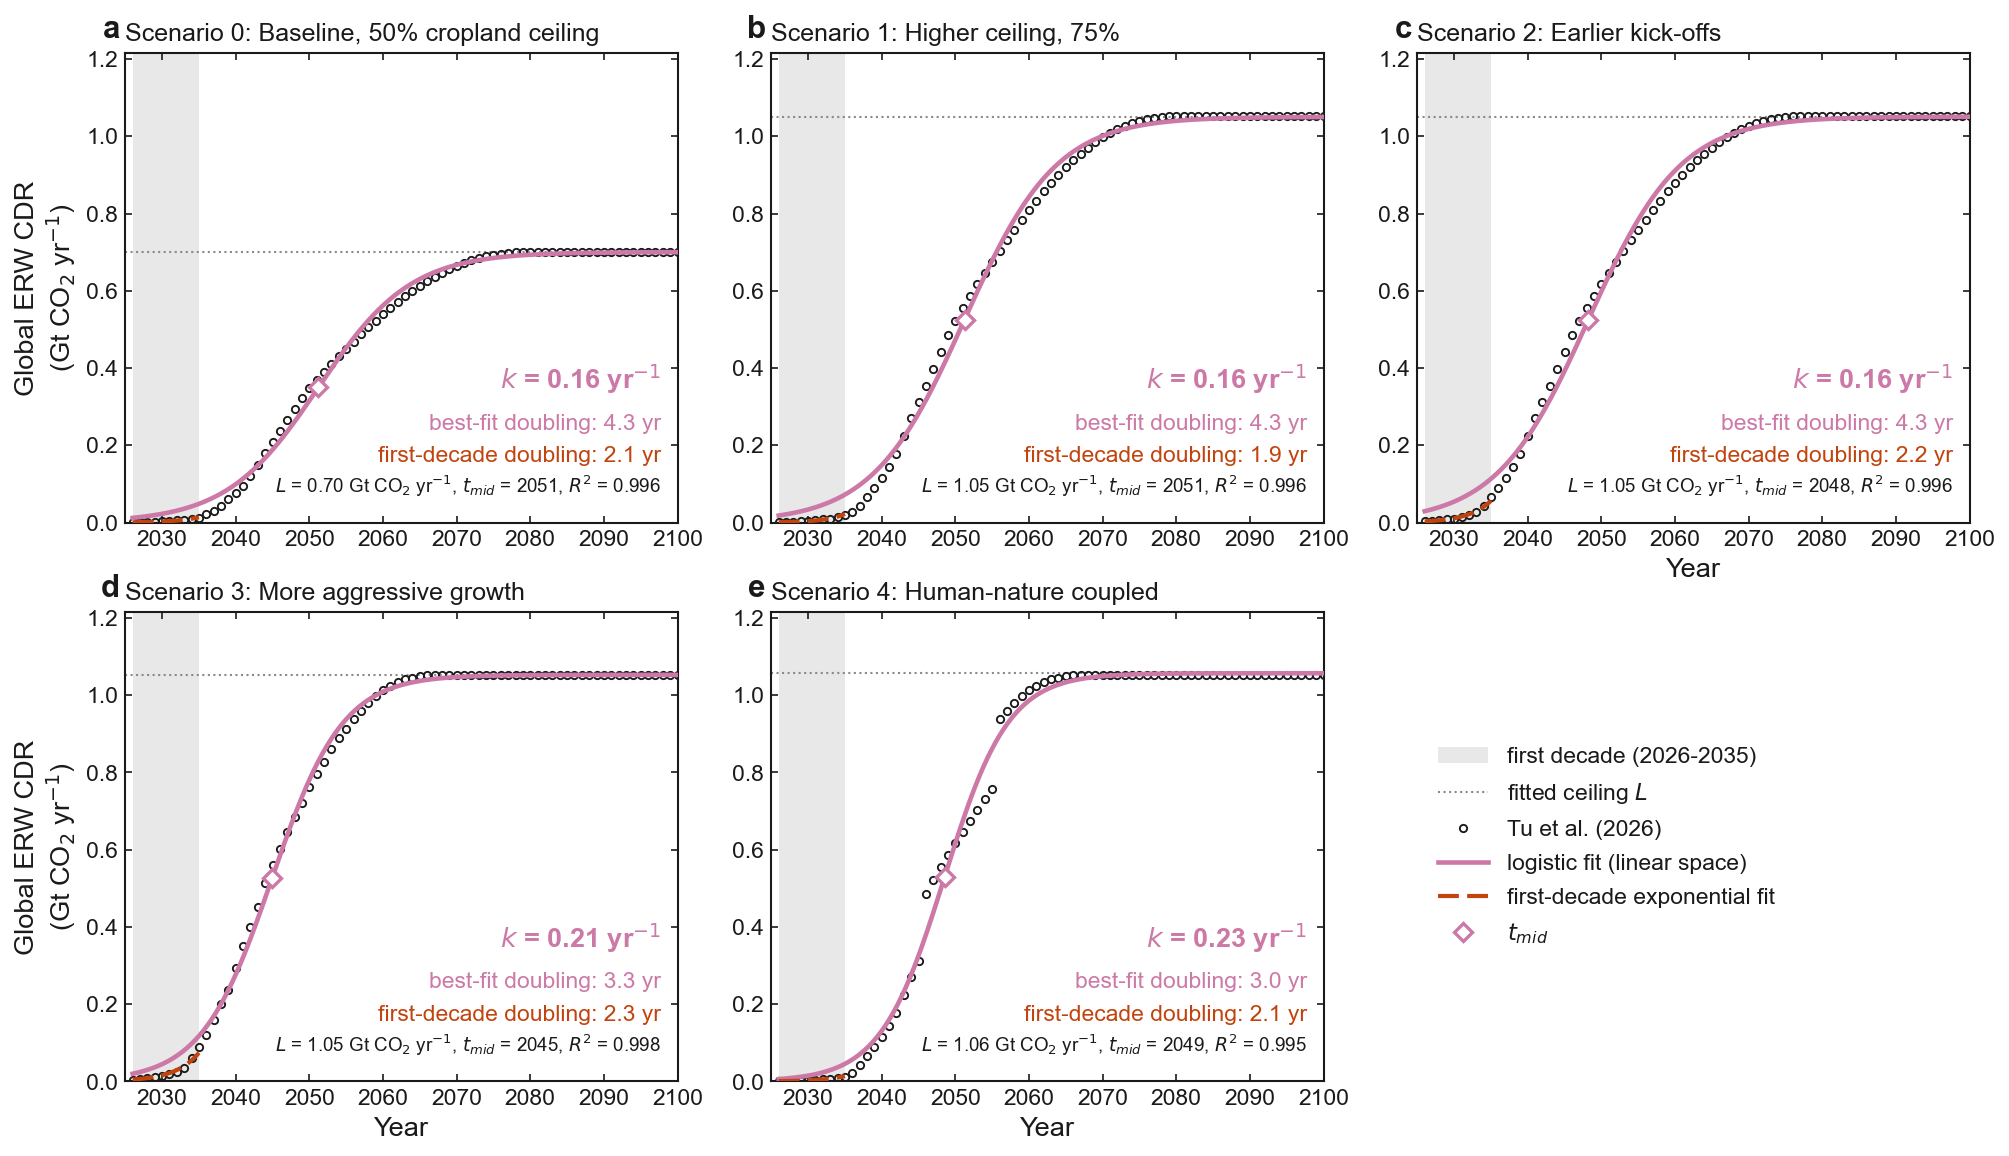

In [8]:
# ———————————————————————————————————
SAVE_ON   = True
FIT_SPACE = "linear"   # fit drawn and annotated in a-e: "linear" or "log"
LOG_Y     = False
# ———————————————————————————————————
t_fine   = np.linspace(years.min(), years.max(), 400)
t_decade = np.linspace(*FIRST_DECADE, 50)
L_max    = max(fits[s, FIT_SPACE][0] for s in SCENARIOS)

fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.8), dpi=150)
scen_axes = axes.ravel()[:len(SCENARIOS)]

for i, (ax, (s, label)) in enumerate(zip(scen_axes, SCENARIOS.items())):
    L, k, t_mid = fits[s, FIT_SPACE]
    k10, ln_c10 = early[s]
    ax.axvspan(*FIRST_DECADE, color=RAMP_SHADE, alpha=0.6, lw=0, zorder=0,
               label=f"first decade ({FIRST_DECADE[0]}-{FIRST_DECADE[1]})")
    ax.axhline(L, color=CEIL_COLOR, ls=":", lw=1.0, zorder=1, label="fitted ceiling $L$")
    ax.plot(years, tu[s], "o", ms=3.5, mfc="none", mec=DATA_COLOR, mew=0.9, zorder=3,
            label="Tu et al. (2026)")
    ax.plot(t_fine, logistic(t_fine, L, k, t_mid), color=FIT_COLOR, lw=LW, zorder=4,
            label=f"logistic fit ({FIT_SPACE} space)")
    ax.plot(t_decade, np.exp(ln_c10 + k10 * t_decade), color=RAMP_COLOR, lw=2.0, ls=(0, (5, 2)),
            zorder=5, label="first-decade exponential fit")
    ax.plot(t_mid, L / 2, "D", ms=6, color="w", mec=FIT_COLOR, mew=1.6, zorder=5, label="$t_{mid}$")
    ax.text(0.97, 0.27, f"$k$ = {k:.2f} yr$^{{-1}}$", transform=ax.transAxes, ha="right", va="bottom",
            fontsize=FS_LAB, fontweight="bold", color=FIT_COLOR)
    ax.text(0.97, 0.19, f"best-fit doubling: {np.log(2) / k:.1f} yr", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=FS_TICK, color=FIT_COLOR)
    ax.text(0.97, 0.12, f"first-decade doubling: {np.log(2) / k10:.1f} yr", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=FS_TICK, color=RAMP_COLOR)
    ax.text(0.97, 0.05, f"$L$ = {L:.2f} Gt CO$_2$ yr$^{{-1}}$, $t_{{mid}}$ = {t_mid:.0f}, "
                        f"$R^2$ = {r2(tu[s].values, logistic(years, L, k, t_mid)):.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=FS_LEG)
    ax.set_title(f"Scenario {s[-1]}: {label}", fontsize=FS_TITLE - 1, loc="left")

    if LOG_Y:
        ax.set_yscale("log")
        ax.set_ylim(3e-4, L_max * 4)
    else:
        ax.set_ylim(0, L_max * 1.15)
    ax.set_xlim(years.min() - 1, years.max())
    ax.set_xticks(np.arange(2030, 2101, 10))
    if i % 3 == 0:
        ax.set_ylabel("Global ERW CDR\n(Gt CO$_2$ yr$^{-1}$)", fontsize=FS_LAB)
    if i >= len(SCENARIOS) - 3:
        ax.set_xlabel("Year", fontsize=FS_LAB)
# legend in the empty sixth slot
axes[1, 2].axis("off")
axes[1, 2].legend(*scen_axes[0].get_legend_handles_labels(), fontsize=FS_TICK, frameon=False,
                  loc="center left", handlelength=2.2, labelspacing=0.6)

for letter, ax in zip("abcde", scen_axes):
    ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=FS_TICK)
    ax.text(-0.01, 1.02, letter, transform=ax.transAxes, ha="right", va="bottom",
            fontsize=FS_LETTER, fontweight="bold")

fig.tight_layout(h_pad=1.2, w_pad=1.4)
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "panels", f"tu-etal-2026-scurves{'-logy' if LOG_Y else ''}.png"),
                dpi=300, bbox_inches="tight", transparent=False)
plt.show()
plt.close();

In [ ]:
# ---